<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_4_6_pasteurizador_placas_parametrico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Carga termica do pasteurizador: 371.17 kW
Vazao de agua quente (Tq2=75 C): 5.8934 kg/s (21216.4 kg/h)


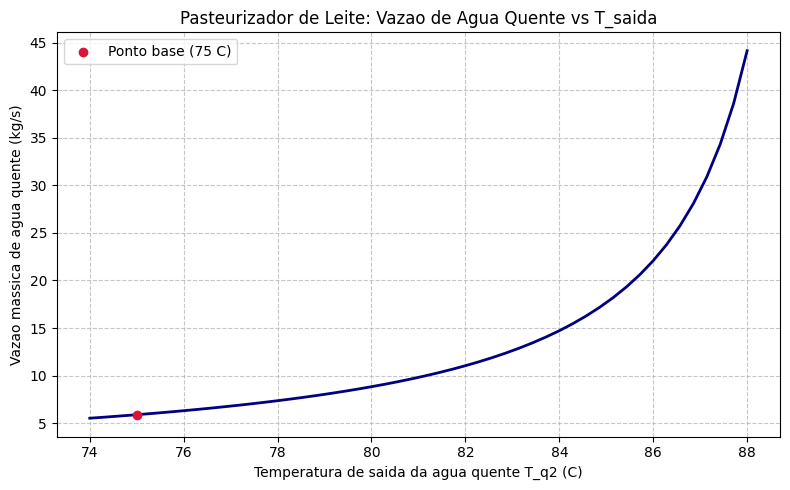

In [1]:
!pip install CoolProp -q
import CoolProp.CoolProp as CP
import numpy as np
import matplotlib.pyplot as plt

m_leite = 5000.0 / 3600.0   # kg/s
cp_leite = 3930.0           # J/(kg.K)
Tf1 = 4.0 + 273.15
Tf2 = 72.0 + 273.15

Q_dot = m_leite * cp_leite * (Tf2 - Tf1)  # W

P_agua = 2e5
Tq1 = 90.0 + 273.15
Tq2_base = 75.0 + 273.15

hq1 = CP.PropsSI('H', 'P', P_agua, 'T', Tq1, 'Water')
hq2_base = CP.PropsSI('H', 'P', P_agua, 'T', Tq2_base, 'Water')
mq_base = Q_dot / (hq1 - hq2_base)

print(f"Carga termica do pasteurizador: {Q_dot/1000:.2f} kW")
print(f"Vazao de agua quente (Tq2=75 C): {mq_base:.4f} kg/s ({mq_base*3600:.1f} kg/h)")

# Analise parametrica: Tq2 variando de 74 C a 88 C
Tq2_C = np.linspace(74.0, 88.0, 50)
mq_lista = []
for t_c in Tq2_C:
    hq2 = CP.PropsSI('H', 'P', P_agua, 'T', t_c + 273.15, 'Water')
    mq_lista.append(Q_dot / (hq1 - hq2))

plt.figure(figsize=(8, 5))
plt.plot(Tq2_C, mq_lista, color='navy', linewidth=2)
plt.scatter([75.0], [mq_base], color='crimson', zorder=5, label='Ponto base (75 C)')
plt.title('Pasteurizador de Leite: Vazao de Agua Quente vs T_saida')
plt.xlabel('Temperatura de saida da agua quente T_q2 (C)')
plt.ylabel('Vazao massica de agua quente (kg/s)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()